In [ ]:
import os

RUN_NAME = f"GRITGATE_gemma8_seed41_VG"
OUTPUT_DIR = os.path.abspath(RUN_NAME)

os.makedirs(OUTPUT_DIR, exist_ok=True)

print(f"All experiment outputs will be saved in:\n{OUTPUT_DIR}")

All experiment outputs will be saved in:
/GRITGATE_gemma4_seed42_IC


In [ ]:
import os
from huggingface_hub import login

hf_token = os.getenv("HF_TOKEN")
login(hf_token)

if hf_token:
    login(hf_token)
    print("Successfully logged in to Hugging Face!")
else:
    print("Hugging Face token not found. Add it in Colab Secrets.")


Hugging Face token not found. Add it in Colab Secrets.


In [ ]:

import sys

!{sys.executable} -m pip install --upgrade pip setuptools wheel
!{sys.executable} -m pip install numpy scikit-learn


!{sys.executable} -m pip install git+https://github.com/AIPHES/emnlp19-moverscore.git

!{sys.executable} -m pip install accelerate rouge-score bert-score nltk torch torchvision pyemd datasets transformers peft "torchao>=0.16.0"
# NOTE: lmms-lab-encoder/RefCOCO is parquet-native (unlike HuggingFaceM4/VQAv2's
# legacy dataset-script format), so the `datasets<4.0.0` pin that VQAv2 required
# is no longer needed here — any current `datasets` release works.

import nltk; nltk.download('wordnet', quiet=True); nltk.download('omw-1.4', quiet=True)
SEED=41

import torch
import gc
import torch.nn as nn
import math
import os
import threading
from typing import Any, Dict, Optional, Tuple, List
from torch.optim import Optimizer
from PIL import Image

import re
import numpy as np
from transformers import EvalPrediction
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from sklearn.metrics import f1_score
import nltk
nltk.download('punkt', quiet=True)


from datasets import load_dataset
from transformers import (
    Gemma3ForConditionalGeneration,
    AutoProcessor,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer,
    TrainerCallback,
    set_seed,
)
from peft import LoraConfig, get_peft_model

# Verify
try:
    from moverscore_v2 import get_idf_dict, word_mover_score
    print("✓ MoverScore installed successfully")
except Exception as e:
    print(f"✗ Error: {e}")

# Patch for numpy.float deprecation in MoverScore
if not hasattr(np, 'float'):
    np.float = float


# =============================================================================
# RefCOCO-specific data helpers (swapped in for the old VQAv2 helpers).
# =============================================================================

def load_image_from_source(image_source):
    """
    Robust image loading for RefCOCO examples.

    lmms-lab-encoder/RefCOCO's `image` column is already a decoded
    PIL.Image (the raw COCO image, with NO region visualization drawn on
    it — see draw_region_indicator() below for that), so this is mostly a
    defensive convert-to-RGB helper.
    """
    try:
        if isinstance(image_source, Image.Image):
            return image_source.convert('RGB') if image_source.mode != 'RGB' else image_source

        # Fallback in case a path/bytes slips through instead of a PIL Image.
        if isinstance(image_source, str) and os.path.exists(image_source):
            image = Image.open(image_source)
            return image.convert('RGB') if image.mode != 'RGB' else image

        if isinstance(image_source, bytes):
            from io import BytesIO
            image = Image.open(BytesIO(image_source))
            return image.convert('RGB') if image.mode != 'RGB' else image

        return None

    except Exception as e:
        print(f"Failed to load image: {e}")
        return None


def draw_region_indicator(image, bbox, color=(255, 0, 0), width_frac=0.006):
    """
    Draw a red RECTANGLE around the referred region.

    Mirrors lmms-eval's own reference implementation for this exact
    dataset (lmms_eval/tasks/refcoco/utils.py, refcoco_bbox_doc_to_visual):
    a plain rectangle at the *exact* bbox, no padding, no circle. bbox is
    COCO-style [x, y, w, h] in pixel coordinates (confirmed against the
    dataset's own schema). We use a slightly thicker line than the
    harness's 1px default, since a 1px line is prone to disappearing once
    the image gets downsampled by the vision processor before the model
    ever sees it.
    """
    from PIL import ImageDraw

    annotated = image.copy()
    if not bbox or len(bbox) != 4:
        return annotated

    x, y, w, h = bbox
    if w <= 0 or h <= 0:
        return annotated

    x0, y0 = x, y
    x1 = min(annotated.width, x + w)
    y1 = min(annotated.height, y + h)

    line_width = max(2, int(round(min(annotated.width, annotated.height) * width_frac)))

    draw = ImageDraw.Draw(annotated)
    draw.rectangle([x0, y0, x1, y1], outline=color, width=line_width)
    return annotated


def extract_raw_answers(example):
    """
    Return the list of raw human reference-expression strings for a
    RefCOCO example, for use with the multi-reference NLG metrics and
    relaxed-match accuracy in make_compute_metrics().

    Unlike VQAv2's dict-based `answers` field, RefCOCO's `answer` field is
    already a flat list of plain strings (the 2-4 human referring
    expressions collected for that region).
    """
    answers_field = example.get('answer')
    if not answers_field:
        return []
    raw = []
    for a in answers_field:
        ans = a.get('answer') if isinstance(a, dict) else a
        if ans:
            raw.append(str(ans))
    return raw


# =============================================================================
# ---- GRIT core (UNCHANGED — copied verbatim from the GatedGrit codebase) ----
# =============================================================================

class KFACAutogradFunction(torch.autograd.Function):
    """Custom autograd function to capture activations and gradients for K-FAC."""

    @staticmethod
    def forward(ctx, module, output, input):
        ctx.module = module
        ctx.save_for_backward(input.detach())
        return output

    @staticmethod
    def backward(ctx, grad_wrt_output):
        module = ctx.module
        input, = ctx.saved_tensors
        manager = module.grit_manager

        if not module.training:
            return None, grad_wrt_output, None

        tick = manager.cov_update_tick.get(module, 0) + 1
        manager.cov_update_tick[module] = tick
        if tick % manager.config.grit_cov_update_freq != 0:
            return None, grad_wrt_output, None

        with torch.no_grad():
            a = input.reshape(-1, input.shape[-1])
            if a.shape[0] > 0 and 'default' in module.lora_A:
                lora_A_T = module.lora_A['default'].weight.data.T.to(device=a.device, dtype=a.dtype, non_blocking=True)
                projected_a = a @ lora_A_T
                a_cov_sample = projected_a.T @ projected_a

                current_cov = manager.a_covs[module].to(a_cov_sample.device)
                n = manager.num_samples_a[module]
                new_n = n + projected_a.shape[0]
                if new_n > 0:
                    updated_cov = (current_cov.float() * n + a_cov_sample.float()) / new_n
                    manager.a_covs[module].copy_(updated_cov.to(dtype=manager.a_covs[module].dtype))
                    manager.num_samples_a[module] = new_n

            g = grad_wrt_output.reshape(-1, grad_wrt_output.shape[-1])
            if g.shape[0] > 0 and 'default' in module.lora_B:
                lora_B = module.lora_B['default'].weight.data.to(device=g.device, dtype=g.dtype, non_blocking=True)
                projected_g = g @ lora_B
                g_cov_sample = projected_g.T @ projected_g

                current_cov = manager.g_covs[module].to(g_cov_sample.device)
                n = manager.num_samples_g[module]
                new_n = n + projected_g.shape[0]
                if new_n > 0:
                    updated_cov = (current_cov.float() * n + g_cov_sample.float()) / new_n
                    manager.g_covs[module].copy_(updated_cov.to(dtype=manager.g_covs[module].dtype))
                    manager.num_samples_g[module] = new_n

        return None, grad_wrt_output, None


class GRITConfig:
    """Configuration for GRIT training on Gemma 3-4B-IT models."""

    def __init__(self):
        # Gemma 3-4B-IT model ID
        self.model_id = "google/gemma-3-4b-it"
        self.batch_size = 1
        self.gradient_accumulation_steps = 4
        self.num_epochs = 3 # SCALING
        self.learning_rate = 5e-5
        self.precision = "bf16"
        self.max_length = 1024  # Gemma 3 supports up to 128K, but we keep it practical

        # LoRA configuration
        self.lora_rank = 8
        self.lora_alpha = 16
        self.lora_dropout = 0.05

        # Gemma 3 target modules (language model attention + MLP)
        # Based on Gemma architecture: attention projections and MLP projections
        self.lora_target_modules = [
            "q_proj",      # Query projection
            "k_proj",      # Key projection
            "v_proj"      # Value projection
            # "o_proj",      # Output projection
            # "gate_proj",   # MLP gate projection
            # "up_proj",     # MLP up projection
            # "down_proj",   # MLP down projection
        ]

        # Vision encoder LoRA (SigLIP encoder in Gemma 3)
        self.apply_lora_to_vision = True
        self.vision_lora_modules = [
            "q_proj",      # Vision encoder Q projection
            "k_proj",      # Vision encoder K projection
            "v_proj"      # Vision encoder V projection
            # "o_proj",      # Vision encoder output projection
        ]

        # GRIT hyperparameters
        self.kfac_update_freq = 150 # 1 to 10
        self.kfac_damping = 0.005
        self.kfac_min_samples = 64 # 1 to 128
        self.reprojection_freq = 50
        self.reprojection_k = 2
        self.grit_cov_update_freq = 2 # 2 to 1

        self.use_two_sided_reprojection = True
        self.use_supergates = True
        self.supergate_floor = 0.05

        self.enable_rank_adaptation = True # true to false
        self.rank_adaptation_threshold = 0.99
        self.min_lora_rank = 4

        self.regularizer_warmup_steps = 150
        self.reprojection_warmup_steps = 200 # 200 to 10000
        self.rank_adaptation_start_step = 250
        self.ng_warmup_steps = 75

        # Dataset configuration
        # lmms-lab-encoder/RefCOCO is parquet-native (no trust_remote_code
        # needed). It's a repackaged *evaluation-only* version of RefCOCO:
        # it ships only val/test/testA/testB — there is no "train" split.
        # All four splits carry real reference-expression answers (unlike
        # VQAv2's blind test), so we repurpose "val" (the largest split)
        # as our train source, and testA/testB as validation/test.
        self.dataset_name = "lmms-lab-encoder/RefCOCO"
        self.num_workers = 0
        self.pin_memory = True
        self.drop_last = True

        self.lambda_kfac = 5e-6
        self.lambda_reproj = 5e-5

        self.log_fisher_spectrum = True
        self.log_top_eigs = 8
        self.log_eig_heatmaps = True
        self.log_eigs_bar = False
        self.log_eig_heatmaps_modules = 4
        self.log_eff_rank_on_inversion = False
        self.log_final_eff_rank = True
        self.kfac_inversion_device = 'cpu'

        self.answer_max_length = 512
        self.ignore_index = -100

        # RefCOCO reference captions are a handful of words. Capping
        # generation length keeps eval fast and matches the short targets
        # (used both by GritTrainer.prediction_step's model.generate call
        # and reported here for reference).
        self.generation_max_new_tokens = 64


class GRITManager:
    """Manager for GRIT on Gemma 3-4B-IT models."""

    def __init__(self, model, config, device):
        self.model = model
        self.config = config
        self.device = device
        self.global_step = 0
        self.backward_step = 0
        self.loss_history = []
        self.loss_history_capacity = 20
        self.last_kfac_update_step = 0
        self.last_reprojection_step = 0
        self.a_covs = {}
        self.g_covs = {}
        self.a_invs = {}
        self.g_invs = {}
        self.num_samples_a = {}
        self.num_samples_g = {}
        self.cov_update_tick = {}
        self.optimized_modules = []
        self.use_supergates = True
        self.supergate_floor = 0.05
        self.supergates = {}

        self.factors_are_ready = False
        self._last_Va_k = {}
        self._last_Vg_k = {}
        self._instrument_model()
        print("GRITManager: Initialization complete for Gemma 3-4B-IT model.")
        print(f"Optimizing {len(self.optimized_modules)} LoRA modules across vision + language towers.")

    def _compute_effective_rank(self, cov: torch.Tensor) -> float:
        """Entropy-based effective rank: exp(H(p)), p = λ / trace(cov)."""
        try:
            with torch.no_grad():
                evals = torch.linalg.eigvalsh(cov.float())
                evals = torch.clamp(evals, min=0.0)
                total = float(evals.sum().item())
                if not math.isfinite(total) or total <= 0.0:
                    return 0.0
                p = (evals / total).clamp_min(1e-12)
                entropy = float((-(p * torch.log(p)).sum()).item())
                r_eff = math.exp(entropy)
                n = int(cov.shape[0])
                if not math.isfinite(r_eff):
                    return 0.0
                return float(max(0.0, min(n, r_eff)))
        except Exception:
            return 0.0

    def _instrument_model(self):
        """Instrument both vision and language LoRA modules for Gemma 3."""
        from peft.tuners.lora import LoraLayer
        from peft.tuners.lora.layer import Linear as LoraLinear

        vision_modules = 0
        language_modules = 0

        for name, module in self.model.named_modules():
            if isinstance(module, LoraLayer) and module.r.get('default', 0) > 0 and isinstance(module.base_layer, nn.Linear):
                module.lora_name = name
                module.grit_manager = self

                name_lower = name.lower()
                # Gemma 3 vision tower detection patterns
                # SigLIP vision encoder is typically under "vision_tower" or "vision_model"
                is_vision = any([
                    'vision_tower' in name_lower,
                    'vision_model' in name_lower,
                    'vision_encoder' in name_lower,
                    'visual' in name_lower and 'language' not in name_lower,
                    name.startswith('model.vision'),
                    name.startswith('vision_tower'),
                ])

                self.num_samples_a[module] = 0
                self.num_samples_g[module] = 0
                self.cov_update_tick[module] = 0

                module.original_forward = module.forward
                def new_forward(self, x=None, *args, **kwargs):
                    if x is None:
                        x = kwargs.get("hidden_states", None)
                        if x is None and len(args) > 0:
                            x = args[0]
                    y = self.original_forward(x, *args, **kwargs)
                    return KFACAutogradFunction.apply(self, y, x)

                module.forward = new_forward.__get__(module, LoraLayer)

                r = module.r['default']
                cov_device = self.device if torch.cuda.is_available() else torch.device('cpu')
                self.a_covs[module] = torch.zeros((r, r), device=cov_device, dtype=torch.float16)
                self.g_covs[module] = torch.zeros((r, r), device=cov_device, dtype=torch.float16)
                self.optimized_modules.append(module)

                if is_vision:
                    vision_modules += 1
                else:
                    language_modules += 1

        print(f"Instrumented {vision_modules} vision modules + {language_modules} language modules")
        print(f"Total LoRA modules with K-FAC: {len(self.optimized_modules)}")

    def _get_adaptive_freq(self, base_freq, min_freq=1, max_freq=1000, window=20):
        if len(self.loss_history) < window:
            return base_freq
        recent_losses = self.loss_history[-window:]
        first_half = sum(recent_losses[:window//2]) / (window//2)
        second_half = sum(recent_losses[window//2:]) / (window//2)
        if second_half < first_half * 0.99:
            new_freq = int(base_freq * 1.5)
        else:
            new_freq = int(base_freq * 0.75)
        return max(min_freq, min(new_freq, max_freq))

    def step(self, loss=None):
        self.global_step += 1
        if loss is not None:
            self.loss_history.append(loss)
            if len(self.loss_history) > self.loss_history_capacity:
                self.loss_history = self.loss_history[-self.loss_history_capacity:]

        if len(self.loss_history) > 10:
            loss_variance = torch.tensor(self.loss_history).var().item()
            self.config.kfac_damping = max(1e-6, min(0.01, 0.001 + math.sqrt(loss_variance)))

        kfac_freq = self._get_adaptive_freq(self.config.kfac_update_freq)
        if self.global_step - self.last_kfac_update_step >= kfac_freq:
            self.update_and_invert_factors()
            self.last_kfac_update_step = self.global_step

        reproj_freq = self._get_adaptive_freq(self.config.reprojection_freq, min_freq=1, max_freq=2000)
        if self.global_step >= int(getattr(self.config, 'reprojection_warmup_steps', 0) or 0) and \
           self.global_step - self.last_reprojection_step >= reproj_freq:
            self.neural_reprojection()
            self.last_reprojection_step = self.global_step

    def update_and_invert_factors(self):
        print(f"\nGRITManager: Inverting K-FAC factors at step {self.global_step}...")
        if not hasattr(self, "_scripted_invert_fn") or self._scripted_invert_fn is None:
            self._scripted_invert_fn = torch.jit.script(jit_invert_tensor_pair)
        scripted_invert_fn = self._scripted_invert_fn

        for module in self.optimized_modules:
            min_samples = getattr(self.config, 'kfac_min_samples', 128)
            if self.num_samples_a.get(module, 0) < min_samples or self.num_samples_g.get(module, 0) < min_samples:
                continue

            inv_device = str(getattr(self.config, 'kfac_inversion_device', 'cpu') or 'cpu')
            if inv_device == 'cuda' and torch.cuda.is_available():
                device_for_inv = torch.device('cuda')
            else:
                device_for_inv = torch.device('cpu')

            a_cov = self.a_covs[module].detach().to(device=device_for_inv, dtype=torch.float32)
            g_cov = self.g_covs[module].detach().to(device=device_for_inv, dtype=torch.float32)

            a_inv, g_inv = scripted_invert_fn(a_cov=a_cov, g_cov=g_cov, kfac_damping=self.config.kfac_damping)
            if a_inv.numel() > 0 and g_inv.numel() > 0:
                self.a_invs[module] = a_inv.to('cpu')
                self.g_invs[module] = g_inv.to('cpu')
            #  SUPERGATES: compute after Fisher inversion
                if self.use_supergates:
                    self.supergates[module] = self.compute_supergates(module)


        self.factors_are_ready = True



    def compute_supergates(self, module):
        """
        Rank-wise gates derived from Fisher eigenvalues.
        Shape: [r]
        """
        cov = self.a_covs[module].detach().float().cpu()

        # Eigenvalues only (directions handled by K-FAC)
        evals = torch.linalg.eigvalsh(cov)
        evals = torch.clamp(evals, min=1e-8)

        # Normalize to probability simplex
        gates = evals / evals.sum()

        # Avoid dead ranks
        gates = torch.clamp(gates, min=self.supergate_floor)
        gates = gates / gates.sum()

        return gates.to(self.device)

    def log_supergate_stats(self):
        print("\n===== SUPERGATE STATS =====")

        if len(self.supergates) == 0:
            print("No supergates found (self.supergates is empty).")
            return

        for module, g in self.supergates.items():
            if g is None or g.numel() == 0:
                continue

            g = g.detach().float().cpu()

            p = g / (g.sum() + 1e-8)
            entropy = (-p * torch.log(p + 1e-8)).sum().item()

            name = getattr(module, "lora_name", module.__class__.__name__)

            print(
                f"{name}: "
                f"mean={g.mean().item():.4f}, "
                f"std={g.std().item():.4f}, "
                f"min={g.min().item():.4f}, "
                f"max={g.max().item():.4f}, "
                f"H={entropy:.4f}"
            )




    def log_final_effective_ranks(self):
        if not getattr(self.config, 'log_final_eff_rank', True):
            return
        try:
            for module in self.optimized_modules:
                a_cov = self.a_covs[module].detach().to(device='cpu', dtype=torch.float32)
                g_cov = self.g_covs[module].detach().to(device='cpu', dtype=torch.float32)
                r_eff_a = self._compute_effective_rank(a_cov)
                r_eff_g = self._compute_effective_rank(g_cov)
                print(f"Fisher/{module.lora_name}/eff_rank_a: {r_eff_a:.4f}")
                print(f"Fisher/{module.lora_name}/eff_rank_g: {r_eff_g:.4f}")
        except Exception:
            pass

    def log_final_raw_ranks(self):
        try:
            for module in self.optimized_modules:
                base_r = int(module.r['default']) if hasattr(module, 'r') and 'default' in module.r else 0
                Va = getattr(self, '_last_Va_k', {}).get(module, None)
                Vg = getattr(self, '_last_Vg_k', {}).get(module, None)
                k_a = int(Va.shape[1]) if Va is not None and Va.numel() > 0 else base_r
                k_b = int(Vg.shape[1]) if Vg is not None and Vg.numel() > 0 else k_a
                print(f"Fisher/{module.lora_name}/final_k_a: {k_a}")
                print(f"Fisher/{module.lora_name}/final_k_b: {k_b}")
        except Exception:
            pass

    def precondition_gradients(self):
        if not self.factors_are_ready:
            return

        with torch.no_grad():
            ng_warmup = int(getattr(self.config, 'ng_warmup_steps', 0) or 0)
            if self.global_step < ng_warmup:
                return

            _total_nat_norm_sq = torch.tensor(0.0, device=self.device)

            for module in self.optimized_modules:
                if module not in self.a_invs or module not in self.g_invs:
                    continue

                lora_a = module.lora_A['default']
                lora_b = module.lora_B['default']

                if (lora_a is None or lora_b is None or
                    lora_a.weight.grad is None or lora_b.weight.grad is None):
                    continue

                a_inv_f32 = self.a_invs[module].to(self.device, dtype=torch.float32)
                g_inv_f32 = self.g_invs[module].to(self.device, dtype=torch.float32)

                grad_b_f32 = lora_b.weight.grad.detach().to(torch.float32)
                preconditioned_b_grad_f32 = grad_b_f32 @ g_inv_f32

                grad_a_f32 = lora_a.weight.grad.detach().to(torch.float32)
                r = module.r['default']
                if r > 0:
                    grad_a_f32 = grad_a_f32.view(r, -1)
                preconditioned_a_grad_f32 = a_inv_f32 @ grad_a_f32
                # ===== SUPERGATES: rank-wise gradient scaling =====
                if self.use_supergates:
                    gates = self.supergates.get(module, None)
                    if gates is not None:
                        # LoRA-A: scale rows (rank dimension)
                        preconditioned_a_grad_f32 *= gates.view(-1, 1)

                        # LoRA-B: scale columns (rank dimension)
                        preconditioned_b_grad_f32 *= gates.view(1, -1)


                _total_nat_norm_sq = _total_nat_norm_sq + preconditioned_a_grad_f32.pow(2).sum() + preconditioned_b_grad_f32.pow(2).sum()

                preconditioned_a_grad_f32 = torch.nan_to_num(preconditioned_a_grad_f32, nan=0.0, posinf=0.0, neginf=0.0)
                preconditioned_b_grad_f32 = torch.nan_to_num(preconditioned_b_grad_f32, nan=0.0, posinf=0.0, neginf=0.0)
                preconditioned_a_grad_f32 = torch.clamp(preconditioned_a_grad_f32, min=-1e6, max=1e6)
                preconditioned_b_grad_f32 = torch.clamp(preconditioned_b_grad_f32, min=-1e6, max=1e6)

                lora_a.weight.grad.copy_(preconditioned_a_grad_f32.to(lora_a.weight.grad.dtype))
                lora_b.weight.grad.copy_(preconditioned_b_grad_f32.to(lora_b.weight.grad.dtype))

                del a_inv_f32, g_inv_f32, grad_a_f32, grad_b_f32, preconditioned_a_grad_f32, preconditioned_b_grad_f32

    def neural_reprojection(self):
        print(f"\nGRITManager: Neural reprojection at step {self.global_step}...")
        initial_params = 0
        final_params = 0

        with torch.no_grad():
            for module in self.optimized_modules:
                if hasattr(module, 'in_features') and hasattr(module, 'out_features'):
                    initial_params += module.r['default'] * (module.in_features + module.out_features)

            for module in self.optimized_modules:
                try:
                    lora_a = module.lora_A['default']
                    lora_b = module.lora_B['default']
                    if lora_a is None or lora_b is None:
                        continue

                    A = lora_a.weight.data.float()
                    B = lora_b.weight.data.float()
                    r = A.shape[0]
                    k = r
                    M = self.a_covs[module].float()

                    if torch.isnan(M).any() or torch.isinf(M).any():
                        final_params += r * (module.in_features + module.out_features)
                        continue

                    min_samples = int(getattr(self.config, 'kfac_min_samples', 128) or 128)
                    if self.num_samples_a.get(module, 0) < min_samples:
                        final_params += r * (module.in_features + module.out_features)
                        continue

                    if self.config.enable_rank_adaptation and r > self.config.min_lora_rank and \
                       self.global_step >= int(getattr(self.config, 'rank_adaptation_start_step', 0) or 0):
                        evals_a, V_a = torch.linalg.eigh(self.a_covs[module].float())
                        order_a = torch.argsort(evals_a, descending=True)
                        V_a = V_a[:, order_a]
                        evals_a = evals_a[order_a]
                        total_energy = torch.sum(evals_a)
                        if total_energy > 1e-6:
                            cumulative_energy = torch.cumsum(evals_a, dim=0) / total_energy
                            k = (cumulative_energy < self.config.rank_adaptation_threshold).sum().item() + 1
                        k = max(k, self.config.min_lora_rank)
                        k = min(k, r)
                        V_a_k = V_a[:, :k]

                        try:
                            g_cov_m = self.g_covs.get(module, None)
                            if getattr(self.config, 'use_two_sided_reprojection', False) and g_cov_m is not None and self.num_samples_g.get(module, 0) >= min_samples:
                                evals_g, V_g = torch.linalg.eigh(g_cov_m.float())
                                order_g = torch.argsort(evals_g, descending=True)
                                V_g_k = V_g[:, order_g][:, :k]
                            else:
                                V_g_k = V_a_k
                        except Exception:
                            V_g_k = V_a_k
                    else:
                        k = min(self.config.reprojection_k, r)
                        evals_a, V_a = torch.linalg.eigh(self.a_covs[module].float())
                        order_a = torch.argsort(evals_a, descending=True)
                        V_a_k = V_a[:, order_a][:, :k]

                        try:
                            g_cov_m = self.g_covs.get(module, None)
                            if getattr(self.config, 'use_two_sided_reprojection', False) and g_cov_m is not None and self.num_samples_g.get(module, 0) >= min_samples:
                                evals_g, V_g = torch.linalg.eigh(g_cov_m.float())
                                order_g = torch.argsort(evals_g, descending=True)
                                V_g_k = V_g[:, order_g][:, :k]
                            else:
                                V_g_k = V_a_k
                        except Exception:
                            V_g_k = V_a_k

                    self._last_Va_k[module] = V_a_k.detach().cpu()
                    self._last_Vg_k[module] = V_g_k.detach().cpu()

                    V_a_k_d = V_a_k.to(device=A.device, dtype=A.dtype, non_blocking=True)
                    V_g_k_d = V_g_k.to(device=B.device, dtype=A.dtype, non_blocking=True)
                    A_proj = V_a_k_d.T @ A
                    B_proj = B @ V_g_k_d
                    A_new = V_a_k_d @ A_proj
                    B_new = B_proj @ V_g_k_d.T
                    lora_a.weight.data.copy_(A_new.to(lora_a.weight.dtype))
                    lora_b.weight.data.copy_(B_new.to(lora_b.weight.dtype))

                    if hasattr(module, 'in_features') and hasattr(module, 'out_features'):
                        final_params += k * (module.in_features + module.out_features)

                except Exception as e:
                    print(f"Error during reprojection for {module.lora_name}: {e}")
                    if hasattr(module, 'in_features') and hasattr(module, 'out_features'):
                        final_params += module.r['default'] * (module.in_features + module.out_features)

        if initial_params > 0:
            param_reduction = initial_params - final_params
            reduction_percent = (param_reduction / initial_params) * 100
            print(f"Neural reprojection: {initial_params:,} -> {final_params:,} ({reduction_percent:.2f}% reduction)")

        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.synchronize()


def jit_invert_tensor_pair(a_cov: torch.Tensor, g_cov: torch.Tensor, kfac_damping: float):
    with torch.no_grad():
        base_damping = float(max(kfac_damping, 1e-6))
        a_cov_f = a_cov.float(); a_cov_f = 0.5 * (a_cov_f + a_cov_f.T)
        g_cov_f = g_cov.float(); g_cov_f = 0.5 * (g_cov_f + g_cov_f.T)
        n_a = int(a_cov_f.shape[0]); n_g = int(g_cov_f.shape[0])
        dev = a_cov_f.device
        I_a = torch.eye(n_a, device=dev); I_g = torch.eye(n_g, device=dev)
        scales = [1.0, 3.0, 10.0, 30.0, 100.0, 300.0]
        for s in scales:
            damp_a = float(base_damping * s)
            damp_g = float(base_damping * s)
            L_a, info_a = torch.linalg.cholesky_ex(a_cov_f + damp_a * I_a)
            L_g, info_g = torch.linalg.cholesky_ex(g_cov_f + damp_g * I_g)
            if int(info_a.item()) == 0 and int(info_g.item()) == 0:
                a_inv = torch.cholesky_inverse(L_a).float()
                g_inv = torch.cholesky_inverse(L_g).float()
                return a_inv, g_inv
        return torch.empty(0, device=dev), torch.empty(0, device=dev)


class GritOptimizer(Optimizer):
    """Wrapper that applies GRIT preconditioning before the underlying step."""

    def __init__(self, optimizer: Optimizer, grit_manager: 'GRITManager'):
        self.optimizer = optimizer
        self.grit_manager = grit_manager

    @property
    def state(self):
        return self.optimizer.state

    @property
    def param_groups(self):
        return self.optimizer.param_groups

    @param_groups.setter
    def param_groups(self, value):
        self.optimizer.param_groups = value

    def step(self, closure=None):
        if self.grit_manager.factors_are_ready and not getattr(self.grit_manager, "_preconditioned", False):
            self.grit_manager.precondition_gradients()
        self.optimizer.step(closure)

    def zero_grad(self, set_to_none: bool = False):
        self.optimizer.zero_grad(set_to_none=set_to_none)

    def add_param_group(self, param_group: dict):
        self.optimizer.add_param_group(param_group)

    def state_dict(self):
        return self.optimizer.state_dict()

    def load_state_dict(self, state_dict: dict):
        self.optimizer.load_state_dict(state_dict)

    def __repr__(self):
        return f"GritOptimizer({self.optimizer.__repr__()})"


class GritCallback(TrainerCallback):
    def __init__(self, grit_manager):
        self.grit_manager = grit_manager

    def on_step_end(self, args, state, control, **kwargs):
        last_loss = state.log_history[-1].get("loss") if state.log_history else None
        self.grit_manager.step(loss=last_loss)
        if self.grit_manager.global_step == 1:
            self.grit_manager.log_supergate_stats()


    def on_train_end(self, args, state, control, **kwargs):
        try:
            self.grit_manager.log_final_effective_ranks()
        except Exception:
            pass
        try:
            self.grit_manager.log_final_raw_ranks()
        except Exception:
            pass
        self.grit_manager.log_supergate_stats()
        torch.save(
            {m.lora_name: g.detach().cpu() for m, g in self.grit_manager.supergates.items()},
            "supergates.pt"
        )


class GritTrainer(Seq2SeqTrainer):
    """Seq2SeqTrainer subclass that injects GRIT preconditioning and regularizers.

    Only `prediction_step` below is adapted for RefCOCO (prompt-only
    generation using each example's `prompt_length`). Every other method —
    create_optimizer_and_scheduler, compute_loss, training_step,
    optimizer_step, evaluate — is the untouched GRIT logic.
    """

    def __init__(self, processor, grit_manager, eval_answers_buffer, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.processor = processor
        self.grit_manager = grit_manager
        # Mutable dict shared with make_compute_metrics(), used to pass
        # the raw per-example human reference expressions (popped out of
        # each batch below) through to compute_metrics for the
        # multi-reference NLG metrics / relaxed-match accuracy, since
        # EvalPrediction only carries decoded predictions/labels.
        self.eval_answers_buffer = eval_answers_buffer
        try:
            setattr(self.grit_manager, "_last_grad_clip_cap", float(getattr(self.args, "max_grad_norm", 0.0)))
        except Exception:
            pass
        print("GritTrainer: Initialized with GRIT for Gemma 3-4B-IT model.")

    def create_optimizer_and_scheduler(self, num_training_steps: int):
        super().create_optimizer_and_scheduler(num_training_steps)
        if self.optimizer is not None:
            print("Wrapping the optimizer with GRIT preconditioning logic.")
            self.optimizer = GritOptimizer(self.optimizer, self.grit_manager)

    def compute_loss(self, model, inputs, return_outputs=False):
        outputs = model(**inputs)
        base_loss = outputs["loss"] if isinstance(outputs, dict) else outputs.loss

        lambda_k = getattr(self.grit_manager.config, "lambda_kfac", 0.0)
        lambda_r = getattr(self.grit_manager.config, "lambda_reproj", 0.0)

        warmup_steps = int(getattr(self.grit_manager.config, "regularizer_warmup_steps", 0) or 0)
        if warmup_steps > 0:
            prog = min(1.0, max(0.0, self.grit_manager.global_step / float(warmup_steps)))
            lambda_k = float(lambda_k) * prog
            lambda_r = float(lambda_r) * prog

        curv_reg = torch.tensor(0.0, device=base_loss.device)
        reproj_reg = torch.tensor(0.0, device=base_loss.device)

        for module in getattr(self.grit_manager, "optimized_modules", []):
            lora_a = module.lora_A['default'] if 'default' in module.lora_A else None
            lora_b = module.lora_B['default'] if 'default' in module.lora_B else None
            if lora_a is None or lora_b is None:
                continue

            A = lora_a.weight
            B = lora_b.weight

            a_cov = self.grit_manager.a_covs.get(module, None)
            g_cov = self.grit_manager.g_covs.get(module, None)

            if a_cov is not None:
                A_f = A.float()
                a_cov_f = a_cov.to(A_f.device, dtype=A_f.dtype)
                curv_reg = curv_reg + ((a_cov_f @ A_f) * A_f).sum()

            if g_cov is not None:
                B_f = B.float()
                g_cov_f = g_cov.to(B_f.device, dtype=B_f.dtype)
                curv_reg = curv_reg + ((B_f @ g_cov_f) * B_f).sum()

            Va_cache = getattr(self.grit_manager, "_last_Va_k", {})
            Vg_cache = getattr(self.grit_manager, "_last_Vg_k", {})
            V_a_k = Va_cache.get(module, None)
            V_g_k = Vg_cache.get(module, None)

            if V_a_k is None and a_cov is not None:
                try:
                    evals, evecs = torch.linalg.eigh(a_cov.float())
                    order = torch.argsort(evals, descending=True)
                    evecs = evecs[:, order]
                    total = torch.clamp(evals.sum(), min=1e-8)
                    threshold = float(self.grit_manager.config.rank_adaptation_threshold)
                    if self.grit_manager.global_step < int(getattr(self.grit_manager.config, 'rank_adaptation_start_step', 0) or 0):
                        k = min(self.grit_manager.config.reprojection_k, A.shape[0])
                    else:
                        k = int((torch.cumsum(evals, 0) / total < threshold).sum().item()) + 1
                    k = max(min(k, A.shape[0]), self.grit_manager.config.min_lora_rank)
                    V_a_k = evecs[:, :k]

                    if V_g_k is None:
                        try:
                            if (getattr(self.grit_manager.config, 'use_two_sided_reprojection', False)
                                and g_cov is not None
                                and self.grit_manager.num_samples_g.get(module, 0) >= int(getattr(self.grit_manager.config, 'kfac_min_samples', 128) or 128)):
                                evals_g, V_gmat = torch.linalg.eigh(g_cov.float())
                                order_g = torch.argsort(evals_g, descending=True)
                                V_g_k = V_gmat[:, order_g][:, :k]
                            else:
                                V_g_k = V_a_k
                        except Exception:
                            V_g_k = V_a_k
                except Exception:
                    V_a_k = None
                    V_g_k = None

            if V_a_k is not None and V_a_k.numel() > 0:
                A_f = A.float(); B_f = B.float()
                device, dtype = A_f.device, A_f.dtype
                V_a_k_d = V_a_k.to(device=device, dtype=dtype, non_blocking=True)
                V_g_k_d = (V_g_k if V_g_k is not None else V_a_k).to(device=device, dtype=dtype, non_blocking=True)
                P_a = V_a_k_d @ V_a_k_d.T
                I_a = torch.eye(P_a.shape[0], device=device, dtype=dtype)
                P_g = V_g_k_d @ V_g_k_d.T
                I_g = torch.eye(P_g.shape[0], device=device, dtype=dtype)
                A_res = (I_a - P_a) @ A_f
                B_res = B_f @ (I_g - P_g)
                reproj_reg = reproj_reg + (A_res.pow(2).sum() + B_res.pow(2).sum())

        loss = base_loss + lambda_k * curv_reg + lambda_r * reproj_reg
        return (loss, outputs) if return_outputs else loss

    def training_step(self, model, inputs, num_items_in_batch=None):
        model.train()
        inputs = self._prepare_inputs(inputs)
        with self.compute_loss_context_manager():
            loss = self.compute_loss(model, inputs)
        if self.args.n_gpu > 1:
            loss = loss.mean()
        self.accelerator.backward(loss)
        return loss.detach() / self.args.gradient_accumulation_steps

    def optimizer_step(self, *args, **kwargs):
        setattr(self.grit_manager, "_preconditioned", False)
        if getattr(self.grit_manager, "factors_are_ready", False):
            self.grit_manager.precondition_gradients()
            setattr(self.grit_manager, "_preconditioned", True)
        return super().optimizer_step(*args, **kwargs)

    def evaluate(self, *args, **kwargs):
        print("\nClearing VRAM before evaluation...")
        gc.collect()
        torch.cuda.empty_cache()
        self.eval_answers_buffer["answers"] = []
        return super().evaluate(*args, **kwargs)

    def prediction_step(
        self,
        model: nn.Module,
        inputs: Dict[str, torch.Tensor],
        prediction_loss_only: bool,
        ignore_keys: Optional[list] = None,
    ) -> Tuple[Optional[torch.Tensor], Optional[torch.Tensor], Optional[torch.Tensor]]:
        """
        RefCOCO-adapted prediction step. GRIT-relevant behavior (loss via
        self.compute_loss, which still applies the curvature/reprojection
        regularizers) is unchanged; only the generation path is adapted.

        `inputs["input_ids"]` (built by tokenize_vqa below) is
        [prompt][answer][eos] for every split, train and eval alike —
        correct for training's teacher-forced loss, but wrong for calling
        model.generate(), which must never see the answer. We use each
        example's `prompt_length` to build a prompt-only, left-padded copy
        of the inputs before generating, so the model actually produces a
        caption instead of being asked to "continue" past the reference.
        """
        has_labels = "labels" in inputs
        if has_labels:
            labels = inputs.pop("labels")
        else:
            labels = None

        # Pull the raw human-answer lists out before anything touches the
        # model — they're plain Python lists, not tensors, and
        # model.generate()/forward() would choke on an unexpected kwarg.
        vqa_answers_batch = inputs.pop("vqa_answers", None)
        if vqa_answers_batch is not None:
            self.eval_answers_buffer["answers"].extend(vqa_answers_batch)

        # Pull prompt_length out too — it's metadata for us, not a real
        # model input.
        prompt_lengths = inputs.pop("prompt_length", None)

        input_ids = inputs["input_ids"]
        input_len = input_ids.shape[1]

        if prompt_lengths is not None:
            attn = inputs["attention_mask"]
            pad_id = self.processor.tokenizer.pad_token_id
            trimmed_ids = [input_ids[i, : int(prompt_lengths[i])] for i in range(input_ids.shape[0])]
            trimmed_mask = [attn[i, : int(prompt_lengths[i])] for i in range(attn.shape[0])]
            max_p = max(t.shape[0] for t in trimmed_ids)

            # Re-pad on the LEFT (matches processor.padding_side="left",
            # which the model/generate expects for batched decoding).
            gen_input_ids = torch.full(
                (len(trimmed_ids), max_p), pad_id, dtype=input_ids.dtype, device=input_ids.device
            )
            gen_attention_mask = torch.zeros(
                (len(trimmed_mask), max_p), dtype=attn.dtype, device=attn.device
            )
            for i, (ids_i, mask_i) in enumerate(zip(trimmed_ids, trimmed_mask)):
                gen_input_ids[i, max_p - ids_i.shape[0]:] = ids_i
                gen_attention_mask[i, max_p - mask_i.shape[0]:] = mask_i

            gen_inputs = dict(inputs)
            gen_inputs["input_ids"] = gen_input_ids
            gen_inputs["attention_mask"] = gen_attention_mask

            if "token_type_ids" in inputs:
                tt = inputs["token_type_ids"]
                trimmed_tt = [tt[i, : int(prompt_lengths[i])] for i in range(tt.shape[0])]
                gen_tt = torch.zeros((len(trimmed_tt), max_p), dtype=tt.dtype, device=tt.device)
                for i, tt_i in enumerate(trimmed_tt):
                    gen_tt[i, max_p - tt_i.shape[0]:] = tt_i
                gen_inputs["token_type_ids"] = gen_tt
            # pixel_values is per-example (whole image), unaffected by
            # sequence-length trimming — carried over unchanged via dict(inputs).

            gen_input_len = gen_input_ids.shape[1]
        else:
            # No prompt_length metadata (e.g. an older cached dataset) —
            # fall back to the old (unsafe) behavior rather than crashing,
            # but this shouldn't happen with datasets from tokenize_vqa.
            gen_inputs = inputs
            gen_input_len = input_len

        with torch.no_grad():
            if prediction_loss_only:
                outputs = model(**inputs)
                loss = outputs.loss if has_labels else None
                return (loss, None, None)

            # Generate from the PROMPT ONLY. Capped max_new_tokens (RefCOCO
            # references are a handful of words) plus a small min_new_tokens
            # so the model can't just emit EOS immediately and give us an
            # empty, unscoreable caption to evaluate.
            generated_tokens = model.generate(
                **gen_inputs,
                max_new_tokens=self.grit_manager.config.generation_max_new_tokens,
                min_new_tokens=2,
                do_sample=False,
                pad_token_id=self.processor.tokenizer.pad_token_id,
                eos_token_id=self.processor.tokenizer.eos_token_id,
            )

            # Slice to generated part only (answer)
            generated_tokens = generated_tokens[:, gen_input_len:]

            # Loss (full inputs for compute_loss) — uses the FULL
            # [prompt][answer] sequence, since teacher-forced loss (and its
            # GRIT curvature/reprojection regularizers) needs the real
            # answer.
            loss = None
            if has_labels:
                inputs_copy = inputs.copy()
                inputs_copy["labels"] = labels
                loss = self.compute_loss(model, inputs_copy).detach()

        # Labels processing
        if labels is not None:
            if labels.dim() == 3:
                labels = torch.argmax(labels, dim=-1)
            elif labels.dim() == 1:
                batch_size = input_ids.shape[0]
                labels = labels.view(batch_size, -1)

        return loss, generated_tokens, labels


def main():
    set_seed(SEED)
    config = GRITConfig()

    config.kfac_min_samples = 256 #256
    config.kfac_update_freq = 150 #150
    config.kfac_damping = 0.005
    config.reprojection_warmup_steps = 200
    config.rank_adaptation_start_step = 500
    config.reprojection_freq = 300
    config.use_two_sided_reprojection = True

    print("Loading processor and model for Gemma 3-4B-IT (RefCOCO)...")
    processor = AutoProcessor.from_pretrained(
        config.model_id,
        token = hf_token,
        trust_remote_code=True,
        padding_side="left",
    )


    if processor.tokenizer.pad_token is None:
        processor.tokenizer.pad_token = processor.tokenizer.eos_token

    model = Gemma3ForConditionalGeneration.from_pretrained(
        config.model_id,
        token=hf_token,
        torch_dtype=torch.bfloat16,
        trust_remote_code=True,
    )

    # Target modules for Gemma 3
    target_modules = config.lora_target_modules.copy()

    lora_config = LoraConfig(
        r=config.lora_rank,
        lora_alpha=config.lora_alpha,
        target_modules=target_modules,
        lora_dropout=config.lora_dropout,
        bias="none",
        task_type="CAUSAL_LM",
        inference_mode=False,
        use_rslora=True,
    )

    model = get_peft_model(model, lora_config)
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total_params = sum(p.numel() for p in model.parameters())

    print(f"Trainable params: {trainable_params:,}")
    print(f"Total params: {total_params:,}")
    print(f"Percentage: {100 * trainable_params / total_params:.3f}%")

    model.enable_input_require_grads()
    model.config.use_cache = False

    print("Loading RefCOCO dataset with splits...")
    # Parquet-native, so no trust_remote_code / streaming workaround
    # needed — this dataset is small (17.6K rows total).
    full_dataset = load_dataset(config.dataset_name)

    # NOTE: this repackaged dataset has no "train" split — only
    # val/test/testA/testB, all with real reference-expression answers.
    # We repurpose "val" (largest, 8.8K) as our train source, and
    # testA/testB as validation/test.
    train_dataset = full_dataset["val"].shuffle(seed=SEED).select(range(8000))
    val_dataset = full_dataset["testA"].shuffle(seed=SEED).select(range(1000))
    test_dataset = full_dataset["testB"].shuffle(seed=SEED).select(range(1000))

    print(f"Final splits → Train: {len(train_dataset)}, Val: {len(val_dataset)}, Test: {len(test_dataset)}")

    def tokenize_vqa(example):
        """
        Process RefCOCO examples: draw the referred region, then build a
        real (prompt + answer) training sequence.

        Builds one real sequence: [prompt_tokens][answer_tokens][eos], and
        masks the labels for the prompt portion with -100 so loss is only
        computed on the actual answer + eos. `prompt_length` is carried
        through so GritTrainer.prediction_step can reconstruct a
        prompt-only input before calling generate() at eval time.
        """
        try:
            if 'image' not in example or example['image'] is None:
                return None

            image = load_image_from_source(example['image'])

            if image is None:
                return None

            if not isinstance(image, Image.Image):
                return None
            if image.mode != 'RGB':
                image = image.convert('RGB')

            # RefCOCO's raw image has no visualization baked in — draw the
            # referred region as a red rectangle using the ground-truth bbox.
            bbox = example.get('bbox')
            image = draw_region_indicator(image, bbox)

            # Matches lmms-eval's own task definition for this exact
            # dataset (lmms_eval/tasks/refcoco/utils.py,
            # refcoco_doc_to_text), which hardcodes this instruction
            # rather than using the dataset's own `question` column.
            question = "Provide a short description for this region."

            # The base instruct model's default habit is to write a full
            # explanatory paragraph, but the references are short (1-4
            # word) noun phrases. Making the brevity requirement explicit
            # in the prompt lets the model lean on instruction-following
            # it already has, which should help ROUGE-L/METEOR well
            # before a small LoRA adapter alone would fix it.
            question = f"{question} Respond with only the short description itself (a few words), with no explanation or extra text."

            # `answer` is a list of 2-4 human referring expressions for the
            # region; train against the first one (raw list is kept
            # separately for the multi-reference metrics via
            # extract_raw_answers).
            answers_list = example.get('answer') or []
            answer = (answers_list[0] if answers_list else '').strip()

            if not question or not answer:
                return None

            messages = [
                {
                    "role": "user",
                    "content": [
                        {"type": "image"},
                        {"type": "text", "text": question}
                    ]
                }
            ]

            text_prompt = processor.apply_chat_template(
                messages,
                tokenize=False,
                add_generation_prompt=True
            )

            # Tokenize the PROMPT (with image) alone, no padding here. We
            # deliberately don't pass max_length/truncation on the prompt:
            # the prompt (including image tokens) must never be truncated,
            # or the model loses the image/instruction it needs.
            prompt_inputs = processor(
                text=[text_prompt],
                images=[image],
                return_tensors="pt",
                padding=False,
            )

            prompt_ids = prompt_inputs['input_ids'].squeeze(0)
            prompt_mask = prompt_inputs['attention_mask'].squeeze(0)
            token_type_ids = prompt_inputs.get('token_type_ids', None)
            if token_type_ids is not None:
                token_type_ids = token_type_ids.squeeze(0)

            if not isinstance(prompt_ids, torch.Tensor):
                prompt_ids = torch.tensor(prompt_ids, dtype=torch.long)
            if not isinstance(prompt_mask, torch.Tensor):
                prompt_mask = torch.tensor(prompt_mask, dtype=torch.long)
            if token_type_ids is not None and not isinstance(token_type_ids, torch.Tensor):
                token_type_ids = torch.tensor(token_type_ids, dtype=torch.long)

            if prompt_ids.shape[0] >= config.max_length:
                # Prompt alone (usually dominated by image tokens) already
                # doesn't leave room for any answer — skip this example
                # rather than truncating the image context.
                return None

            eos_id = processor.tokenizer.eos_token_id
            answer_tokens = processor.tokenizer(
                answer,
                add_special_tokens=False,
                return_tensors="pt"
            )['input_ids'].squeeze(0)
            if not isinstance(answer_tokens, torch.Tensor):
                answer_tokens = torch.tensor(answer_tokens, dtype=torch.long)

            # Append EOS to the training target so the model learns to
            # stop generating instead of rambling indefinitely.
            eos_tensor = torch.tensor([eos_id], dtype=answer_tokens.dtype)
            answer_tokens = torch.cat([answer_tokens, eos_tensor], dim=0)

            # If prompt + answer would exceed max_length, truncate the
            # ANSWER (never the prompt/image) to fit.
            remaining_budget = config.max_length - prompt_ids.shape[0]
            if remaining_budget <= 0:
                return None
            if answer_tokens.shape[0] > remaining_budget:
                # keep room for the eos token we appended
                answer_tokens = torch.cat(
                    [answer_tokens[: remaining_budget - 1], eos_tensor], dim=0
                )

            # Build the real training sequence: prompt followed by answer.
            input_ids = torch.cat([prompt_ids, answer_tokens], dim=0)
            attention_mask = torch.cat(
                [prompt_mask, torch.ones_like(answer_tokens)], dim=0
            )
            labels = torch.cat(
                [
                    torch.full_like(prompt_ids, config.ignore_index),
                    answer_tokens.clone(),
                ],
                dim=0,
            )

            if token_type_ids is not None:
                token_type_ids = torch.cat(
                    [token_type_ids, torch.zeros_like(answer_tokens)], dim=0
                )

            output = {
                'input_ids': input_ids,
                'attention_mask': attention_mask,
                'labels': labels,
                # Length of the prompt-only portion of input_ids (before
                # answer+eos were appended). Training needs the full
                # [prompt][answer] sequence for teacher forcing, but at
                # eval time model.generate() must only ever see the
                # prompt — GritTrainer.prediction_step uses this to
                # reconstruct a prompt-only input before calling generate().
                'prompt_length': int(prompt_ids.shape[0]),
                # Raw (un-normalized) list of the ~2-4 human answers, kept
                # around purely for the multi-reference NLG metrics at
                # eval time. Not used in training/loss.
                'vqa_answers': extract_raw_answers(example),
            }
            if token_type_ids is not None:
                output['token_type_ids'] = token_type_ids

            if 'pixel_values' in prompt_inputs:
                pixel_values = prompt_inputs['pixel_values']

                if isinstance(pixel_values, torch.Tensor):
                    if pixel_values.dim() >= 2 and pixel_values.shape[0] == 1:
                        pixel_values = pixel_values.squeeze(0)
                    output['pixel_values'] = pixel_values
                elif isinstance(pixel_values, list) and len(pixel_values) > 0:
                    if isinstance(pixel_values[0], torch.Tensor):
                        output['pixel_values'] = pixel_values[0] if len(pixel_values) == 1 else torch.cat(pixel_values, dim=0)

            for key in ['input_ids', 'attention_mask', 'labels', 'token_type_ids']:
                if key in output and not isinstance(output[key], torch.Tensor):
                    print(f"ERROR: {key} is not a tensor: {type(output[key])}")
                    return None

            return output

        except Exception as e:
            print(f"Error processing example: {e}")
            import traceback
            traceback.print_exc()
            return None

    print("Tokenizing datasets...")
    print("Processing training data...")
    tokenized_train_dataset = train_dataset.map(
        tokenize_vqa,
        remove_columns=train_dataset.column_names,
        #num_proc=1,
        #desc="Processing training data",
        load_from_cache_file=False
    )

    print("Filtering valid training samples...")
    tokenized_train_dataset = tokenized_train_dataset.filter(
        lambda x: x is not None and 'input_ids' in x and 'labels' in x,
        desc="Filtering training data"
    )

    print("Processing validation data...")
    tokenized_val_dataset = val_dataset.map(
        tokenize_vqa,
        remove_columns=val_dataset.column_names,
        #num_proc=1,
        #desc="Processing validation data",
        load_from_cache_file=False
    )

    print("Filtering valid validation samples...")
    tokenized_val_dataset = tokenized_val_dataset.filter(
        lambda x: x is not None and 'input_ids' in x and 'labels' in x,
        desc="Filtering validation data"
    )

    print("Processing test data (held out from validation)...")
    tokenized_test_dataset = test_dataset.map(
        tokenize_vqa,
        remove_columns=test_dataset.column_names,
        #num_proc=1,
        #desc="Tokenizing test",
        load_from_cache_file=False,
    )

    print("Filtering valid test samples...")
    tokenized_test_dataset = tokenized_test_dataset.filter(
        lambda x: x is not None and 'input_ids' in x and 'labels' in x,
        desc="Filtering test data"
    )

    train_len = len(tokenized_train_dataset)
    val_len = len(tokenized_val_dataset)
    test_len = len(tokenized_test_dataset)

    if train_len == 0:
        raise ValueError(
            "No training samples after processing. "
            "Possible causes: images not loading correctly, dataset format incompatible, "
            "or all examples failed validation."
        )

    print(f"\nSuccessfully processed datasets:")
    print(f"Training samples: {train_len}")
    print(f"Validation samples: {val_len}")
    print(f"Test samples: {test_len}")

    eff_batch = config.batch_size * config.gradient_accumulation_steps
    total_steps = math.ceil(train_len / eff_batch) * config.num_epochs

    print(f"\nTraining Configuration:")
    print(f"Total training steps: {total_steps}")
    print(f"Effective batch size: {eff_batch}")
    print(f"Steps per epoch: {math.ceil(train_len / eff_batch)}")

    training_args = Seq2SeqTrainingArguments(
        output_dir=f"./results_refcoco_gritgate_gemma4_seed{SEED}",

        per_device_train_batch_size=config.batch_size,
        per_device_eval_batch_size=config.batch_size,
        gradient_accumulation_steps=config.gradient_accumulation_steps,

        num_train_epochs=config.num_epochs,
        learning_rate=config.learning_rate,

        bf16=(config.precision == "bf16"),
        fp16=(config.precision == "fp16"),

        max_grad_norm=1.5,

        gradient_checkpointing=True,
        gradient_checkpointing_kwargs={"use_reentrant": False},

        dataloader_num_workers=config.num_workers,
        dataloader_pin_memory=config.pin_memory,
        dataloader_drop_last=config.drop_last,

        remove_unused_columns=False,
        report_to="none",

        # Final run: no validation/checkpointing during training
        save_strategy="no",
        eval_strategy="no",

        logging_steps=50,
        warmup_steps=100,

        seed=SEED,
        data_seed=SEED,

        optim="adamw_torch",

        prediction_loss_only=False,
        predict_with_generate=True,
    )

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"\nInitializing GRIT on device: {device}")
    grit_manager = GRITManager(model, config, device)


    def collate_fn(batch):
        """Custom collator for Gemma 3 inputs with proper batching."""
        batch = [b for b in batch if b is not None and isinstance(b, dict) and 'input_ids' in b]

        if len(batch) == 0:
            print("WARNING: Empty batch after filtering - creating dummy batch")
            dummy_input_ids = torch.zeros((1, config.max_length), dtype=torch.long)
            dummy_attention_mask = torch.zeros((1, config.max_length), dtype=torch.long)
            dummy_labels = torch.full((1, config.max_length), config.ignore_index, dtype=torch.long)
            dummy_token_type_ids = torch.zeros((1, config.max_length), dtype=torch.long)

            return {
                'input_ids': dummy_input_ids,
                'attention_mask': dummy_attention_mask,
                'labels': dummy_labels,
                'token_type_ids': dummy_token_type_ids,
            }

        try:
            for i, item in enumerate(batch):
                for key in ['input_ids', 'attention_mask', 'labels', 'token_type_ids']:
                    if key in item and not isinstance(item[key], torch.Tensor):
                        batch[i][key] = torch.tensor(item[key], dtype=torch.long)

            input_ids = torch.nn.utils.rnn.pad_sequence(
                [b['input_ids'] for b in batch],
                batch_first=True,
                padding_value=processor.tokenizer.pad_token_id
            )

            attention_mask = torch.nn.utils.rnn.pad_sequence(
                [b['attention_mask'] for b in batch],
                batch_first=True,
                padding_value=0
            )

            labels = torch.nn.utils.rnn.pad_sequence(
                [b['labels'] for b in batch],
                batch_first=True,
                padding_value=config.ignore_index
            )

            output = {
                'input_ids': input_ids,
                'attention_mask': attention_mask,
                'labels': labels,
            }

            if 'token_type_ids' in batch[0]:
                token_type_ids_list = [
                    b['token_type_ids'] for b in batch
                    if 'token_type_ids' in b and isinstance(b['token_type_ids'], torch.Tensor)
                ]
                if token_type_ids_list:
                    token_type_ids = torch.nn.utils.rnn.pad_sequence(
                        token_type_ids_list,
                        batch_first=True,
                        padding_value=0
                    )
                    output['token_type_ids'] = token_type_ids

            if 'pixel_values' in batch[0] and batch[0]['pixel_values'] is not None:
                pixel_values_list = []

                for b in batch:
                    pv = b['pixel_values']

                    if isinstance(pv, list):
                        if len(pv) > 0 and isinstance(pv[0], torch.Tensor):
                            pv = torch.stack(pv) if len(pv) > 1 else pv[0]
                        elif len(pv) > 0 and isinstance(pv[0], list):
                            pv = torch.tensor(pv)
                        else:
                            continue

                    if isinstance(pv, torch.Tensor):
                        while pv.dim() > 0 and pv.shape[0] == 1:
                            pv = pv.squeeze(0)
                        pixel_values_list.append(pv)

                if len(pixel_values_list) > 0:
                    try:
                        output['pixel_values'] = torch.stack(pixel_values_list, dim=0)
                    except RuntimeError:
                        max_shapes = [max(pv.shape[i] for pv in pixel_values_list) for i in range(pixel_values_list[0].dim())]
                        padded_pvs = []
                        for pv in pixel_values_list:
                            if list(pv.shape) != max_shapes:
                                padding = []
                                for i in range(len(max_shapes) - 1, -1, -1):
                                    padding.extend([0, max_shapes[i] - pv.shape[i]])
                                pv = torch.nn.functional.pad(pv, padding)
                            padded_pvs.append(pv)
                        output['pixel_values'] = torch.stack(padded_pvs, dim=0)

            # Pass the raw per-example human answers through untouched
            # (list of lists of strings) — needed for the multi-reference
            # NLG metrics. This is popped out again in
            # GritTrainer.prediction_step before the tensors go to the model.
            output['vqa_answers'] = [b.get('vqa_answers', []) for b in batch]

            # Carry prompt_length through so eval-time generation can trim
            # the answer back out of input_ids before calling
            # model.generate() (see GritTrainer.prediction_step).
            if 'prompt_length' in batch[0]:
                output['prompt_length'] = torch.tensor(
                    [b.get('prompt_length', 0) for b in batch], dtype=torch.long
                )

            return output

        except Exception as e:
            print(f"ERROR in collate_fn: {e}")
            import traceback
            traceback.print_exc()

            dummy_input_ids = torch.zeros((1, config.max_length), dtype=torch.long)
            dummy_attention_mask = torch.zeros((1, config.max_length), dtype=torch.long)
            dummy_labels = torch.full((1, config.max_length), config.ignore_index, dtype=torch.long)
            dummy_token_type_ids = torch.zeros((1, config.max_length), dtype=torch.long)

            return {
                'input_ids': dummy_input_ids,
                'attention_mask': dummy_attention_mask,
                'labels': dummy_labels,
                'token_type_ids': dummy_token_type_ids,
            }

    def make_compute_metrics(processor, eval_answers_buffer):
        import re
        import numpy as np
        from rouge_score import rouge_scorer
        from nltk.translate.meteor_score import meteor_score
        from bert_score import score as bert_score
        from collections import defaultdict
        import nltk
        nltk.download('wordnet', quiet=True)
        nltk.download('omw-1.4', quiet=True)

        # PATCH FOR MOVERSCORE COMPATIBILITY
        import transformers.tokenization_utils_base as tub
        if not hasattr(tub.PreTrainedTokenizerBase, '_moverscore_patched'):
            original_init = tub.PreTrainedTokenizerBase.__init__
            def patched_init(self, *args, **kwargs):
                original_init(self, *args, **kwargs)
                if not hasattr(self, 'max_len'):
                    self.max_len = self.model_max_length
            tub.PreTrainedTokenizerBase.__init__ = patched_init
            tub.PreTrainedTokenizerBase._moverscore_patched = True
            print("✓ Applied moverscore compatibility patch")

        # Now import moverscore
        moverscore_available = False
        try:
            from moverscore_v2 import get_idf_dict, word_mover_score
            moverscore_available = True
            print("✓ MoverScore loaded successfully")
        except ImportError as e:
            print(f"✗ MoverScore not available: {e}")

        scorer = rouge_scorer.RougeScorer(['rougeL'], use_stemmer=True)

        def extract_answer(text):
            """Clean Gemma output safely without truncating content."""

            if text is None:
                return ""

            # Remove special tokens
            text = text.replace("<bos>", "")
            text = text.replace("<eos>", "")
            text = text.replace("<start_of_turn>", "")
            text = text.replace("<end_of_turn>", "")

            # Remove leading 'model' tag if present
            text = re.sub(r"^\s*model\s*", "", text, flags=re.IGNORECASE)

            # Normalize whitespace
            text = re.sub(r"\s+", " ", text).strip()

            return text

        # Official VQA eval answer processing (from the VQA project's
        # vqaEval.py), used so exact-match comparisons for accuracy (and
        # the text-similarity metrics below) aren't broken by trailing
        # punctuation, articles, or number-word vs. digit mismatches.
        _vqa_contractions = {
            "aint": "ain't", "arent": "aren't", "cant": "can't", "couldve": "could've",
            "couldnt": "couldn't", "didnt": "didn't", "doesnt": "doesn't", "dont": "don't",
            "hadnt": "hadn't", "hasnt": "hasn't", "havent": "haven't", "hed": "he'd",
            "hes": "he's", "im": "i'm", "ive": "i've", "isnt": "isn't", "its": "it's",
            "lets": "let's", "shant": "shan't", "shes": "she's", "shouldve": "should've",
            "shouldnt": "shouldn't", "thats": "that's", "theres": "there's", "theyd": "they'd",
            "theyre": "they're", "theyve": "they've", "wasnt": "wasn't", "wed": "we'd",
            "were": "we're", "weve": "we've", "werent": "weren't", "whats": "what's",
            "wheres": "where's", "whos": "who's", "wont": "won't", "wouldve": "would've",
            "wouldnt": "wouldn't", "youd": "you'd", "youre": "you're", "youve": "you've",
        }
        _vqa_number_words = {
            "none": "0", "zero": "0", "one": "1", "two": "2", "three": "3", "four": "4",
            "five": "5", "six": "6", "seven": "7", "eight": "8", "nine": "9", "ten": "10",
        }
        _vqa_articles = {"a", "an", "the"}
        _vqa_punct = [';', '/', '[', ']', '"', '{', '}', '(', ')', '=', '+', '\\',
                      '_', '-', '>', '<', '@', '`', ',', '?', '!', '.', ':']

        def normalize(s):
            """Official VQA-style answer normalization."""
            s = s.lower().strip()
            # Remove punctuation entirely (rather than spacing it out),
            # so "brown." normalizes to "brown", not "brown .".
            for p in _vqa_punct:
                s = s.replace(p, ' ')
            s = re.sub(r"\s+", " ", s).strip()

            words = []
            for word in s.split():
                word = _vqa_number_words.get(word, word)
                if word in _vqa_articles:
                    continue
                word = _vqa_contractions.get(word, word)
                words.append(word)
            return ' '.join(words).strip()

        def compute_vqa_metrics(p: EvalPrediction):
            pred_ids = np.asarray(p.predictions, dtype=np.int64)
            labels = np.asarray(p.label_ids, dtype=np.int64)

            vocab_size = processor.tokenizer.vocab_size
            pad_token_id = processor.tokenizer.pad_token_id

            pred_ids = np.clip(pred_ids, 0, vocab_size - 1)
            labels[labels < 0] = pad_token_id
            labels = np.clip(labels, 0, vocab_size - 1)

            try:
                pred_texts_raw = processor.batch_decode(pred_ids, skip_special_tokens=True)
                label_texts = processor.batch_decode(labels, skip_special_tokens=True)
            except Exception as e:
                print(f"[Metrics] Decode error: {e}")
                return {"rouge_l": 0.0, "meteor": 0.0, "bertscore_f1": 0.0, "moverscore": 0.0, "accuracy": 0.0}

            pred_texts = [extract_answer(t) for t in pred_texts_raw]
            pred_norm = [normalize(t) for t in pred_texts]
            label_norm = [normalize(t) for t in label_texts]

            for i in range(min(3, len(pred_norm))):
                print(f"\n[Sample {i+1}]")
                print(f"Generated: {pred_texts[i][:100]}")
                print(f"Reference: {label_texts[i][:100]}")

            # `labels` only ever encodes answers_list[0] (see tokenize_vqa),
            # i.e. ONE arbitrary human reference out of the 2-4 RefCOCO
            # collects per region. A correct prediction that happens to
            # match reference #2 or #3 instead of #1 would score as a
            # near-total miss on ROUGE-L/METEOR if scored only against
            # label_norm. Instead we feed ALL of the example's raw answers
            # (buffered in eval_answers_buffer by
            # GritTrainer.prediction_step) in as separate reference
            # captions and take the best match across the full reference
            # set — mirroring lmms-eval's own aggregation for this exact
            # dataset (refcoco_aggregation_result).
            raw_answers_list = eval_answers_buffer.get("answers", [])
            use_multi_ref = len(raw_answers_list) == len(pred_norm)

            if use_multi_ref:
                norm_refs_per_example = [
                    [normalize(a) for a in raw_answers if a] or [l]
                    for raw_answers, l in zip(raw_answers_list, label_norm)
                ]
            else:
                print(
                    f"[Metrics] WARNING: buffered answers ({len(raw_answers_list)}) "
                    f"!= predictions ({len(pred_norm)}); falling back to "
                    f"single-reference scoring against the training answer."
                )
                norm_refs_per_example = [[l] for l in label_norm]

            valid_pairs = [
                (p, refs) for p, refs in zip(pred_norm, norm_refs_per_example)
                if p and refs and len(p.split()) > 0
            ]

            # ROUGE-L — max over this example's reference set.
            rouge_ls = []
            for p, refs in valid_pairs:
                best = max(
                    (scorer.score(r, p)['rougeL'].fmeasure for r in refs if r),
                    default=None,
                )
                if best is not None:
                    rouge_ls.append(best)
            rouge_l = np.mean(rouge_ls) if rouge_ls else 0.0

            # METEOR — nltk's meteor_score natively supports multiple
            # references and takes the max internally, so just pass the
            # full reference set instead of a single one.
            meteors = []
            for p, refs in valid_pairs:
                ref_token_lists = [r.split() for r in refs if r]
                if ref_token_lists:
                    meteors.append(meteor_score(ref_token_lists, p.split()))
            meteor = np.mean(meteors) if meteors else 0.0

            # BERTscore / MoverScore need one (pred, ref) string pair per
            # call, so we flatten pred-vs-each-of-its-refs into parallel
            # lists, score everything in one batched call, then take the
            # max back per original example.
            flat_preds, flat_refs, group_idx = [], [], []
            for i, (p, refs) in enumerate(valid_pairs):
                for r in refs:
                    if r:
                        flat_preds.append(p)
                        flat_refs.append(r)
                        group_idx.append(i)

            def _max_per_group(flat_scores, n_groups):
                best = [None] * n_groups
                for idx, s in zip(group_idx, flat_scores):
                    if best[idx] is None or s > best[idx]:
                        best[idx] = s
                return [b for b in best if b is not None]

            # BERTscore
            if flat_preds and flat_refs:
                try:
                    P, R, F1 = bert_score(
                        flat_preds,
                        flat_refs,
                        lang="en",
                        model_type="bert-base-uncased",
                        rescale_with_baseline=False
                    )
                    per_ex_best = _max_per_group(F1.tolist(), len(valid_pairs))
                    bertscore_f1 = float(np.mean(per_ex_best)) if per_ex_best else 0.0
                except Exception as e:
                    print(f"[Metrics] BERTScore error: {e}")
                    bertscore_f1 = 0.0
            else:
                bertscore_f1 = 0.0

            # Accuracy — a relaxed containment match instead of the
            # official VQA leave-one-out soft-accuracy formula. That
            # formula assumes VQA's setting (short, closed-set answers,
            # ~10 annotators) and doesn't transfer well to RefCOCO's
            # free-form referring expressions with only 2-4 annotators: it
            # caps max achievable accuracy below 1.0, and requires an
            # EXACT string match, so a correct caption like "this is an
            # umpire" would never match the reference "umpire". A
            # prediction counts as correct here if it exactly matches,
            # contains, or is contained by, any one of that example's
            # human reference expressions (after normalization). Treat
            # this as a coarse correct/incorrect signal — ROUGE-L / METEOR
            # / BERTScore / MoverScore remain the primary quality metrics.
            print(f"\n[Accuracy Debug] buffered answer-sets: {len(raw_answers_list)} | predictions: {len(pred_norm)}")
            for i in range(min(3, len(raw_answers_list), len(pred_norm))):
                print(f"[Accuracy Debug] Sample {i+1}")
                print(f"  Prediction (normalized): {pred_norm[i]!r}")
                print(f"  Raw human answers       : {raw_answers_list[i]}")
                print(f"  Normalized human answers: {[normalize(a) for a in raw_answers_list[i] if a]}")

            def relaxed_match(pred, ref):
                if not pred or not ref:
                    return False
                if pred == ref:
                    return True
                # Require at least a few characters of real overlap so a
                # single short common word (e.g. "the") can't trivially
                # match — both strings are already normalized (articles
                # stripped, lowercased) at this point.
                if len(ref) >= 3 and ref in pred:
                    return True
                if len(pred) >= 3 and pred in ref:
                    return True
                return False

            if not use_multi_ref:
                matches = [1.0 if relaxed_match(p, l) else 0.0 for p, l in zip(pred_norm, label_norm) if l]
                accuracy = float(np.mean(matches)) if matches else 0.0
            else:
                per_question_accs = []
                for pred, raw_answers in zip(pred_norm, raw_answers_list):
                    norm_answers = [normalize(a) for a in raw_answers if a]
                    if not norm_answers:
                        continue
                    is_correct = any(relaxed_match(pred, ref) for ref in norm_answers)
                    per_question_accs.append(1.0 if is_correct else 0.0)
                accuracy = float(np.mean(per_question_accs)) if per_question_accs else 0.0

            # MoverScore — same flatten-then-max-per-example approach as
            # BERTScore above, using flat_preds/flat_refs/group_idx built
            # earlier from the FULL reference set (not just answers_list[0]).
            moverscore_val = 0.0
            if moverscore_available and flat_preds and flat_refs:
                try:
                    from moverscore_v2 import get_idf_dict, word_mover_score

                    idf_dict_ref = get_idf_dict(flat_refs)
                    idf_dict_hyp = get_idf_dict(flat_preds)

                    scores = word_mover_score(
                        flat_refs,
                        flat_preds,
                        idf_dict_ref,
                        idf_dict_hyp,
                        stop_words=[],
                        n_gram=1,
                        remove_subwords=True
                    )

                    if scores and len(scores) > 0:
                        per_ex_best = _max_per_group(scores, len(valid_pairs))
                        moverscore_val = float(np.mean(per_ex_best)) if per_ex_best else 0.0
                        print(f"[MoverScore] Score: {moverscore_val:.4f}")

                except Exception as e:
                    print(f"[MoverScore] Error: {e}")
                    import traceback
                    traceback.print_exc()

            return {
                "rouge_l": float(rouge_l),
                "meteor": float(meteor),
                "bertscore_f1": float(bertscore_f1),
                "moverscore": float(moverscore_val),
                "accuracy": accuracy,
            }

        return compute_vqa_metrics

    # Shared mutable buffer: GritTrainer.prediction_step fills it with the
    # raw per-question human answers for each eval batch; compute_metrics
    # reads it to compute the multi-reference NLG metrics / relaxed-match
    # accuracy.
    eval_answers_buffer = {"answers": []}

    trainer = GritTrainer(
        processor=processor,
        grit_manager=grit_manager,
        eval_answers_buffer=eval_answers_buffer,
        model=model,
        args=training_args,
        train_dataset=tokenized_train_dataset,
        eval_dataset=tokenized_val_dataset,
        data_collator=collate_fn,
        compute_metrics=make_compute_metrics(processor, eval_answers_buffer),
        callbacks=[GritCallback(grit_manager)],
    )

    print("\n" + "="*80)
    print("STARTING GRIT TRAINING FOR GEMMA 3-4B-IT MODEL ON REFCOCO")
    print("="*80)
    print(f"Model: {config.model_id}")
    print(f"Dataset: {config.dataset_name}")
    print(f"LoRA rank: {config.lora_rank}")
    print(f"Batch size: {config.batch_size} x {config.gradient_accumulation_steps} = {eff_batch}")
    print(f"Learning rate: {config.learning_rate}")
    print(f"Precision: {config.precision}")
    print(f"K-FAC update freq: {config.kfac_update_freq} steps")
    print(f"Reprojection freq: {config.reprojection_freq} steps")
    print(f"Vision LoRA: {'Enabled' if config.apply_lora_to_vision else 'Disabled'}")
    print(f"Rank adaptation: {'Enabled' if config.enable_rank_adaptation else 'Disabled'}")
    print(f"Training samples: {train_len}")
    print(f"Validation samples: {val_len}")
    print(f"Test samples: {test_len}")
    print("="*80 + "\n")

    try:
        print("Beginning training...")
        trainer.train()
        trainer.grit_manager.log_supergate_stats()

        print("\n" + "="*80)
        print("FINAL TEST EVALUATION")
        print("="*80)

        test_results = trainer.evaluate(eval_dataset=tokenized_test_dataset)

        print(f"Test Loss          : {test_results['eval_loss']:.5f}")
        print(f"Test ROUGE-L       : {test_results['eval_rouge_l']:.4f}")
        print(f"Test METEOR        : {test_results['eval_meteor']:.4f}")
        print(f"Test BERTscore F1  : {test_results['eval_bertscore_f1']:.4f}")
        print(f"Test MoverScore    : {test_results['eval_moverscore']:.4f}")
        print(f"Test Accuracy      : {test_results['eval_accuracy']:.4f}")

        print("\n" + "="*80)
        print("Saving final model...")
                # ============================================================
        # SAVE FINAL RESULTS
        # ============================================================

        result = {
            "method": "Gated GRIT",
            "model": config.model_id,
            "task": "RefCOCO",
            "seed": SEED,

            "train_size": train_len,
            "val_size": val_len,
            "test_size": test_len,

            "epochs": config.num_epochs,
            "batch_size": config.batch_size,
            "gradient_accumulation_steps": config.gradient_accumulation_steps,
            "effective_batch_size": eff_batch,
            "optimizer_steps": total_steps,

            "learning_rate": config.learning_rate,
            "precision": config.precision,

            "lora_rank": config.lora_rank,
            "lora_alpha": config.lora_alpha,
            "lora_dropout": config.lora_dropout,

            "language_target_modules": config.lora_target_modules,
            "vision_target_modules": config.vision_lora_modules,

            "kfac_update_freq": config.kfac_update_freq,
            "kfac_min_samples": config.kfac_min_samples,
            "kfac_damping": config.kfac_damping,
            "grit_cov_update_freq": config.grit_cov_update_freq,

            "reprojection_freq": config.reprojection_freq,
            "reprojection_warmup_steps": config.reprojection_warmup_steps,
            "reprojection_k": config.reprojection_k,

            "rank_adaptation_enabled": config.enable_rank_adaptation,
            "rank_adaptation_start_step": config.rank_adaptation_start_step,
            "rank_adaptation_threshold": config.rank_adaptation_threshold,
            "min_lora_rank": config.min_lora_rank,

            "supergates_enabled": config.use_supergates,
            "supergate_floor": config.supergate_floor,

            "lambda_kfac": config.lambda_kfac,
            "lambda_reproj": config.lambda_reproj,

            "test_loss": float(test_results["eval_loss"]),
            "test_rouge_l": float(test_results["eval_rouge_l"]),
            "test_meteor": float(test_results["eval_meteor"]),
            "test_bertscore_f1": float(test_results["eval_bertscore_f1"]),
            "test_moverscore": float(test_results["eval_moverscore"]),
            "test_accuracy": float(test_results["eval_accuracy"]),
        }

        # Save ONE canonical metrics file in the common output folder
        results_path = os.path.join(
            OUTPUT_DIR,
            "results.json"
        )

        with open(results_path, "w") as f:
            json.dump(result, f, indent=2)

        print(f"\n✓ Results saved to: {results_path}")

        print("\n" + "="*80)
        print("TRAINING COMPLETED SUCCESSFULLY")
        print("="*80 + "\n")

    except KeyboardInterrupt:
        print("\n" + "="*80)
        print("TRAINING INTERRUPTED BY USER")
        print("="*80)
        print("Saving checkpoint...")
        try:
            model.save_pretrained("./interrupted_checkpoint_refcoco_grit_gemma3")
            processor.save_pretrained("./interrupted_checkpoint_refcoco_grit_gemma3")
            print("Checkpoint saved to ./interrupted_checkpoint_refcoco_grit_gemma3")
        except Exception as e:
            print(f"Failed to save checkpoint: {e}")

    except Exception as e:
        print("\n" + "="*80)
        print("TRAINING FAILED")
        print("="*80)
        print(f"Error: {e}")
        import traceback
        traceback.print_exc()
        raise

    finally:
        print("\nCleaning up...")
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        print("Cleanup complete")


if __name__ == "__main__":
    main()

  Using cached setuptools-84.0.0-py3-none-any.whl.metadata (6.6 kB)
Using cached setuptools-84.0.0-py3-none-any.whl (818 kB)
  Attempting uninstall: setuptools
    Found existing installation: setuptools 81.0.0
    Uninstalling setuptools-81.0.0:
      Successfully uninstalled setuptools-81.0.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torch 2.11.0+cu128 requires setuptools<82, but you have setuptools 84.0.0 which is incompatible.
  Cloning https://github.com/AIPHES/emnlp19-moverscore.git to ./tmp/pip-req-build-xu6arl7i
  Running command git clone --filter=blob:none --quiet https://github.com/AIPHES/emnlp19-moverscore.git /tmp/pip-req-build-xu6arl7i
  Resolved https://github.com/AIPHES/emnlp19-moverscore.git to commit 0459a3b3b3bd73baa0cc515a355228ee5a2887e0
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparin

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

Trainable params: 4,696,064
Total params: 4,304,775,536
Percentage: 0.109%
Loading RefCOCO dataset with splits...
Final splits → Train: 32, Val: 4, Test: 4
Tokenizing datasets...
Processing training data...


Map:   0%|          | 0/32 [00:00<?, ? examples/s]

... (18 outputs left out)

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



[Accuracy Debug] buffered answer-sets: 4 | predictions: 4
[Accuracy Debug] Sample 1
  Prediction (normalized): 'whole orange segment'
  Raw human answers       : ['orange in bowl', 'top mid orange whole']
  Normalized human answers: ['orange in bowl', 'top mid orange whole']
[Accuracy Debug] Sample 2
  Prediction (normalized): 'kitchen stovetop area'
  Raw human answers       : ['stove', 'stove top', 'stove top']
  Normalized human answers: ['stove', 'stove top', 'stove top']
[Accuracy Debug] Sample 3
  Prediction (normalized): 'crumb covered donut piece'
  Raw human answers       : ['top edge, 3rd donut from right', 'portion of donut at top left of center']
  Normalized human answers: ['top edge 3rd donut from right', 'portion of donut at top left of center']
[MoverScore] Score: 0.5614


Training Loss,Validation Loss,Epoch,Rouge L,Meteor,Bertscore F1,Moverscore,Accuracy
No log,15.637983,3,0.216667,0.148873,0.612408,0.561359,0.250000


Test Loss          : 15.63798
Test ROUGE-L       : 0.2167
Test METEOR        : 0.1489
Test BERTscore F1  : 0.6124
Test MoverScore    : 0.5614
Test Accuracy      : 0.2500

Saving final model...

✓ Results saved to: /GRITGATE_gemma4_seed42_IC/results.json

TRAINING COMPLETED SUCCESSFULLY


Cleaning up...
Cleanup complete


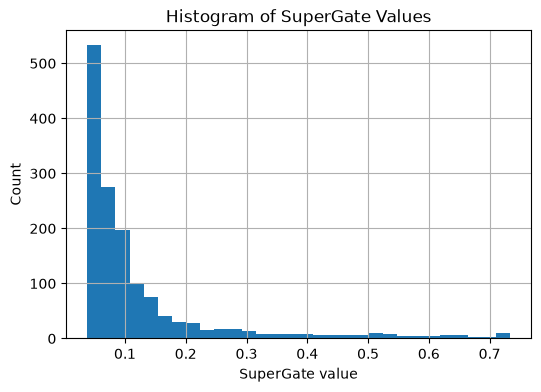

<Figure size 640x480 with 0 Axes>

In [ ]:
import torch
import matplotlib.pyplot as plt

# Load saved supergates
supergates = torch.load("supergates.pt", map_location="cpu")

# Collect all gate values
all_gates = []
for name, g in supergates.items():
    all_gates.extend(g.detach().float().tolist())

all_gates = torch.tensor(all_gates)

# Plot histogram
plt.figure(figsize=(6, 4))
plt.hist(all_gates.numpy(), bins=30)
plt.xlabel("SuperGate value")
plt.ylabel("Count")
plt.title("Histogram of SuperGate Values")
plt.grid(True)
plt.show()
plt.savefig(
    os.path.join(OUTPUT_DIR, "gate_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    os.path.join(OUTPUT_DIR, "supergate_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)

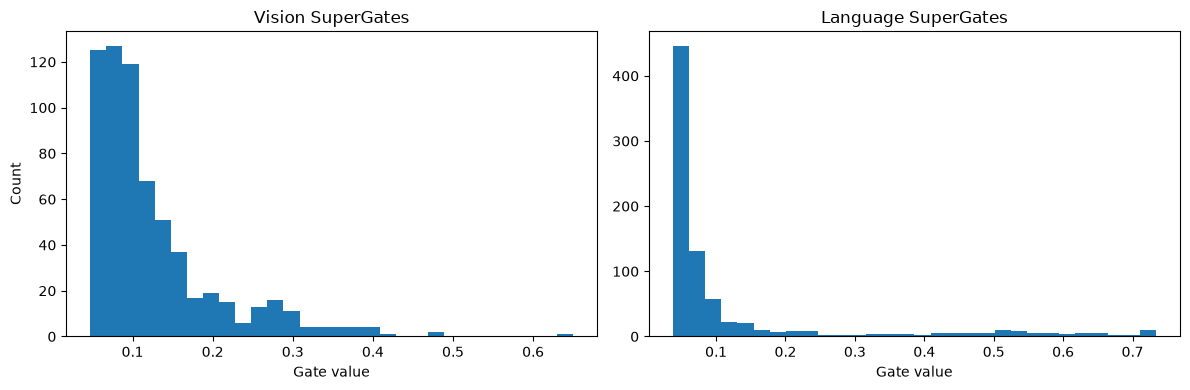

<Figure size 640x480 with 0 Axes>

In [ ]:
vision_gates = []
language_gates = []

for name, g in supergates.items():
    if "vision" in name.lower():
        vision_gates.extend(g.detach().float().tolist())
    else:
        language_gates.extend(g.detach().float().tolist())

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.hist(vision_gates, bins=30)
plt.title("Vision SuperGates")
plt.xlabel("Gate value")
plt.ylabel("Count")

plt.subplot(1, 2, 2)
plt.hist(language_gates, bins=30)
plt.title("Language SuperGates")
plt.xlabel("Gate value")

plt.tight_layout()
plt.show()
plt.savefig(
    os.path.join(OUTPUT_DIR, "Vision_language_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)

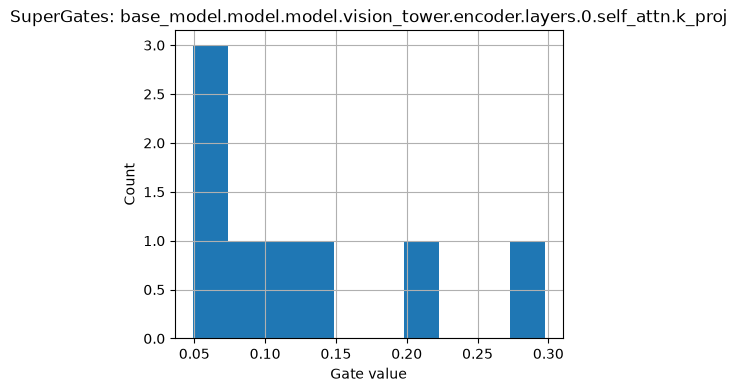

In [ ]:
layer_name = list(supergates.keys())[0]  # or pick manually
g = supergates[layer_name].detach().float()

plt.figure(figsize=(5, 4))
plt.hist(g.numpy(), bins=10)
plt.title(f"SuperGates: {layer_name}")
plt.xlabel("Gate value")
plt.ylabel("Count")
plt.grid(True)
plt.show()

In [ ]:
layer_entropy = []

for name, g in supergates.items():
    g = g.detach().float().cpu()
    p = g / (g.sum() + 1e-8)
    H = (-(p * torch.log(p + 1e-8))).sum().item()

    # crude depth extraction
    depth = int(name.split("layers.")[1].split(".")[0])
    layer_entropy.append((depth, H))

layer_entropy.sort()


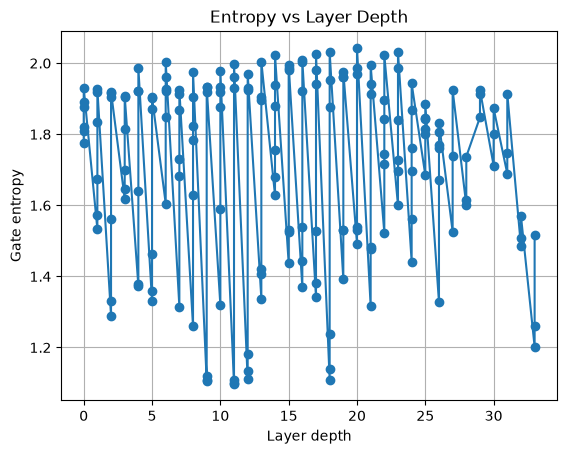

<Figure size 640x480 with 0 Axes>

In [ ]:
import matplotlib.pyplot as plt

d, h = zip(*layer_entropy)
plt.plot(d, h, marker="o")
plt.xlabel("Layer depth")
plt.ylabel("Gate entropy")
plt.title("Entropy vs Layer Depth")
plt.grid(True)
plt.show()
plt.savefig(
    os.path.join(OUTPUT_DIR, "entropy_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)


In [ ]:
import torch
import json
import os

# Load supergates
supergates = torch.load("supergates.pt", map_location="cpu")

# Containers
all_g = []
vision_g = []
language_g = []

# Collect gates
for name, g in supergates.items():
    g = g.detach().float().cpu()
    all_g.append(g)

    if "vision" in name.lower():
        vision_g.append(g)
    else:
        language_g.append(g)

# Summary function
def summarize(gs):
    if not gs:
        return {}

    g = torch.cat(gs)
    p = g / (g.sum() + 1e-8)

    return {
        "mean": g.mean().item(),
        "std": g.std().item(),
        "min": g.min().item(),
        "max": g.max().item(),
        "entropy": (
            -(p * torch.log(p + 1e-8))
        ).sum().item()
    }

# Calculate summaries
gate_analysis = {
    "all": summarize(all_g),
    "vision": summarize(vision_g),
    "language": summarize(language_g),
}

# Print summaries
print("ALL:", gate_analysis["all"])
print("VISION:", gate_analysis["vision"])
print("LANGUAGE:", gate_analysis["language"])


ALL: {'mean': 0.125, 'std': 0.13126657903194427, 'min': 0.038061365485191345, 'max': 0.733570396900177, 'entropy': 6.917717933654785}
VISION: {'mean': 0.125, 'std': 0.07901165634393692, 'min': 0.04725203290581703, 'max': 0.6498814225196838, 'entropy': 6.311118125915527}
LANGUAGE: {'mean': 0.125, 'std': 0.1611679345369339, 'min': 0.038061365485191345, 'max': 0.733570396900177, 'entropy': 6.167693614959717}


In [ ]:
results_path = os.path.join(
    OUTPUT_DIR,
    "results.json"
)

with open(results_path, "r") as f:
    final_results = json.load(f)

final_results["gated_grit_analysis"] = {
    "gate_statistics": gate_analysis
}

with open(results_path, "w") as f:
    json.dump(final_results, f, indent=2)

print(f"\nUpdated results saved to: {results_path}")


Updated results saved to: /GRITGATE_gemma4_seed42_IC/results.json


In [ ]:
nominal_rank = 8  # or 16 / 32 depending on run

eff_ranks = [
    (g > g.min() + 1e-4).sum().item()
    for g in all_g
]
eff_ranks = torch.tensor(eff_ranks)

avg_effective_rank = eff_ranks.float().mean().item()
compression_ratio = avg_effective_rank / nominal_rank

floor = min([g.min().item() for g in all_g])
g_all = torch.cat(all_g)

sparsity = (
    (g_all <= floor + 1e-4)
    .float()
    .mean()
    .item()
)

print("Avg effective rank:", avg_effective_rank)
print("Compression ratio:", compression_ratio)
print(f"Sparsity: {sparsity * 100:.2f}%")


Avg effective rank: 5.519125461578369
Compression ratio: 0.6898906826972961
Sparsity: 0.48%


In [ ]:
import json
import os

results_path = os.path.join(
    OUTPUT_DIR,
    "results.json"
)

with open(results_path, "r") as f:
    final_results = json.load(f)

# Make sure the analysis section exists
if "gated_grit_analysis" not in final_results:
    final_results["gated_grit_analysis"] = {}

final_results["gated_grit_analysis"]["rank_analysis"] = {
    "nominal_rank": nominal_rank,
    "average_effective_rank": avg_effective_rank,
    "compression_ratio": compression_ratio,
    "sparsity": sparsity,
    "sparsity_percent": sparsity * 100,
    "threshold_epsilon": 1e-4
}

with open(results_path, "w") as f:
    json.dump(final_results, f, indent=2)

print(f"\nUpdated results saved to: {results_path}")



Updated results saved to: /GRITGATE_gemma4_seed42_IC/results.json
